<a href="https://colab.research.google.com/github/SilverShadow123/computer_vision/blob/master/PPE_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!nvidia-smi
!pip install -U ultralytics

Mon Nov 23 11:54:55 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   53C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [6]:
from google.colab import drive
drive.mount('/content/drive')

import os

PROJECT_DIR = "/content/drive/MyDrive/PPE_YOLO26"
os.makedirs(PROJECT_DIR, exist_ok=True)

print("Project directory:", PROJECT_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project directory: /content/drive/MyDrive/PPE_YOLO26


In [7]:
import os
import zipfile
import urllib.request

DATASET_URL = (
    "https://github.com/ultralytics/assets/releases/"
    "download/v0.0.0/construction-ppe.zip"
)

ZIP_PATH = "/content/construction-ppe.zip"
DATASET_DIR = "/content/datasets"

os.makedirs(DATASET_DIR, exist_ok=True)

urllib.request.urlretrieve(DATASET_URL, ZIP_PATH)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(DATASET_DIR)

print("Dataset extracted successfully!")

for root, dirs, files in os.walk(DATASET_DIR):
    if any(f.endswith(".yaml") for f in files):
        print(root, files)


Dataset extracted successfully!
/content/datasets/construction-ppe ['README.md', 'data.yaml', 'LICENSE.txt', 'manifest.jsonl']


In [8]:

import glob
import yaml

yaml_files = glob.glob(
    "/content/datasets/**/*.yaml",
    recursive=True
)

print("Available YAML files:", yaml_files)

DATA_YAML = yaml_files[0]

with open(DATA_YAML, "r") as file:
    dataset_config = yaml.safe_load(file)

print(dataset_config)


Available YAML files: ['/content/datasets/construction-ppe/data.yaml']
{'path': 'construction-ppe', 'train': 'images/train', 'val': 'images/val', 'names': {0: 'helmet', 1: 'gloves', 2: 'vest', 3: 'boots', 4: 'goggles', 5: 'Person', 6: 'no_helmet', 7: 'no_goggle', 8: 'no_gloves', 9: 'no_boots', 10: 'forklift', 11: 'no_vest'}}


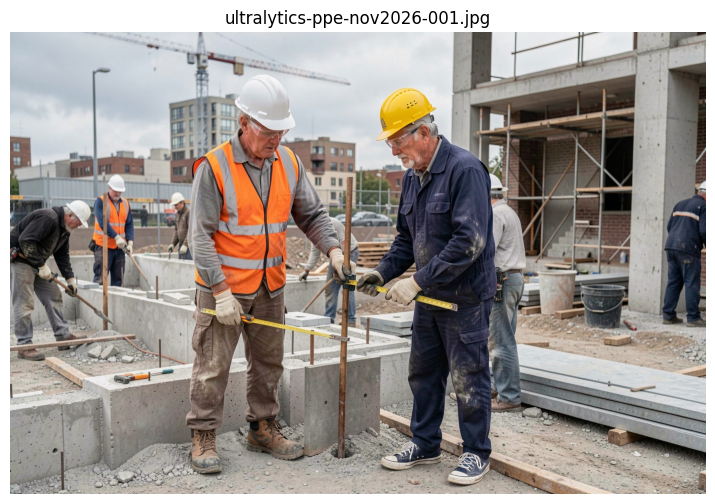

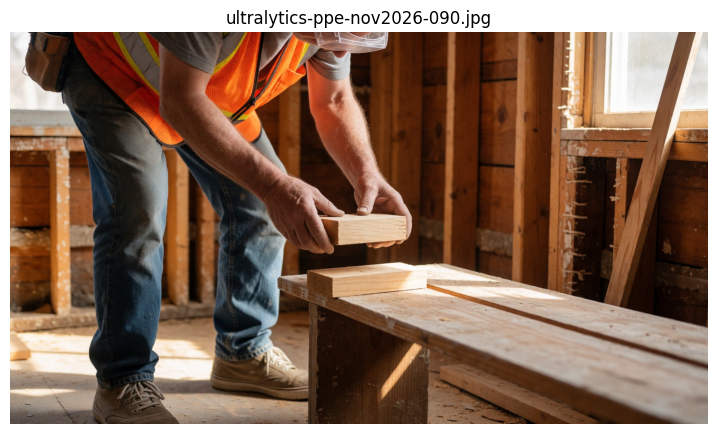

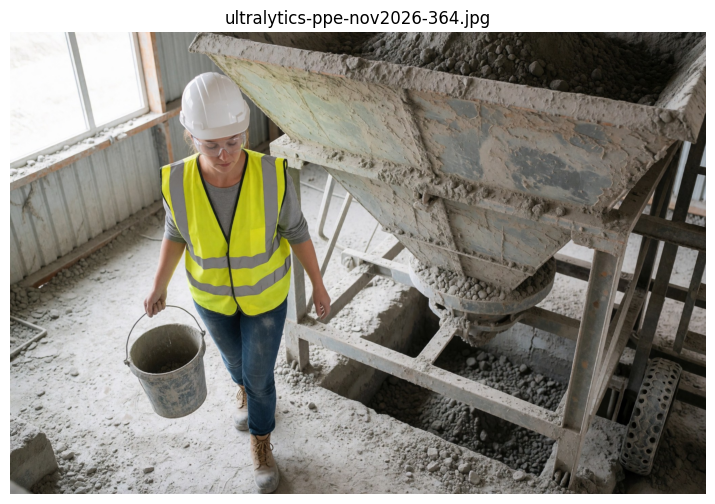

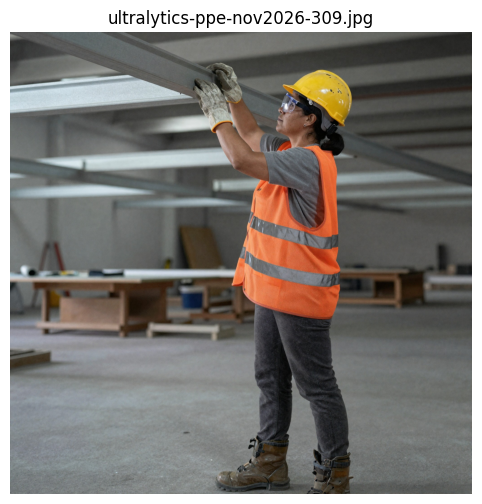

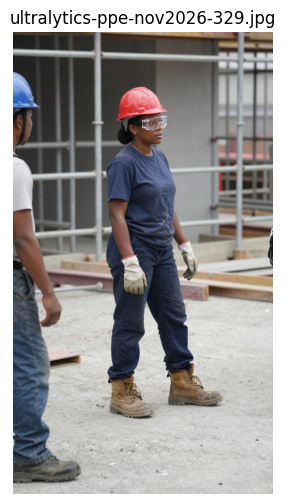

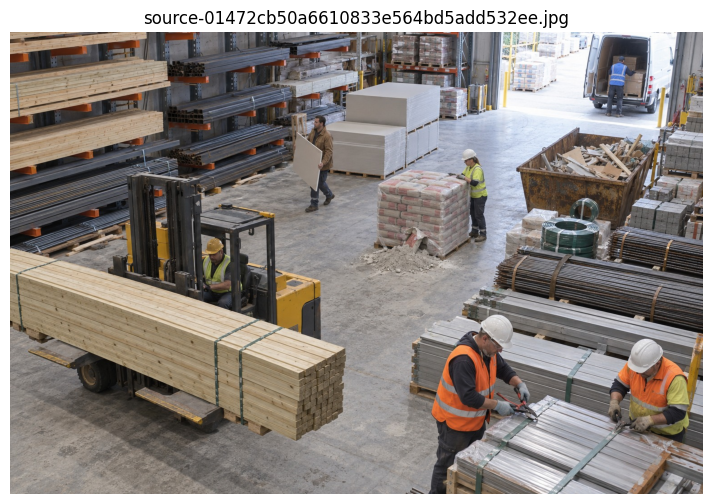

In [9]:

import random
import glob
import cv2
import matplotlib.pyplot as plt

train_path = dataset_config["train"]

if not os.path.isabs(train_path):
    train_path = os.path.join(
        os.path.dirname(DATA_YAML),
        train_path
    )

image_files = glob.glob(
    os.path.join(train_path, "*")
)

image_files = [
    f for f in image_files
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

samples = random.sample(image_files, min(6, len(image_files)))

for image_path in samples:
    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(9, 6))
    plt.imshow(image)
    plt.title(os.path.basename(image_path))
    plt.axis("off")
    plt.show()


In [10]:

from ultralytics import YOLO

model = YOLO("yolo26s.pt")

train_results = model.train(
    data=DATA_YAML,
    epochs=100,
    imgsz=640,
    batch=16,
    patience=20,
    optimizer="auto",
    seed=42,
    deterministic=True,
    workers=4,
    project=PROJECT_DIR,
    name="yolo26s_ppe",
    exist_ok=True,
    plots=True,
    save=True,
    save_period=10,
    device=0
)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/construction-ppe/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript,

In [11]:

best_model_path = os.path.join(
    PROJECT_DIR,
    "yolo26s_ppe",
    "weights",
    "best.pt"
)

best_model = YOLO(best_model_path)

metrics = best_model.val(
    data=DATA_YAML,
    split="val",
    imgsz=640,
    batch=16,
    plots=True,
    save_json=True
)

print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)
print("mAP75:", metrics.box.map75)


Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,469,824 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2704.1±556.9 MB/s, size: 658.3 KB)
val: Scanning /content/datasets/construction-ppe/labels/val.cache... 200 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 200/200 46.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 2.0it/s 6.5s
                   all        200       2961      0.903      0.765       0.82      0.599
                helmet        146        294      0.945      0.874      0.894       0.72
                gloves        136        381      0.906      0.816      0.869        0.7
                  vest        157        340       0.96      0.909      0.926      0.754
                 boots        155        481      0.828      0.778      0.833      0.644
               goggles     

In [12]:

precision = metrics.box.mp
recall = metrics.box.mr

f1_score = (
    2 * precision * recall /
    (precision + recall + 1e-10)
)

print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1_score:.4f}")


Precision: 0.9033
Recall: 0.7652
F1-score: 0.8285


In [13]:

class_names = metrics.names
class_ap = metrics.box.maps

print("CLASS-WISE mAP50-95")

for class_id, ap in enumerate(class_ap):
    print(f"{class_names[class_id]}: {ap:.4f}")


CLASS-WISE mAP50-95
helmet: 0.7203
gloves: 0.7001
vest: 0.7542
boots: 0.6437
goggles: 0.7238
Person: 0.8271
no_helmet: 0.4363
no_goggle: 0.1853
no_gloves: 0.4640
no_boots: 0.6277
forklift: 0.6047
no_vest: 0.5013


BoxPR_curve.png


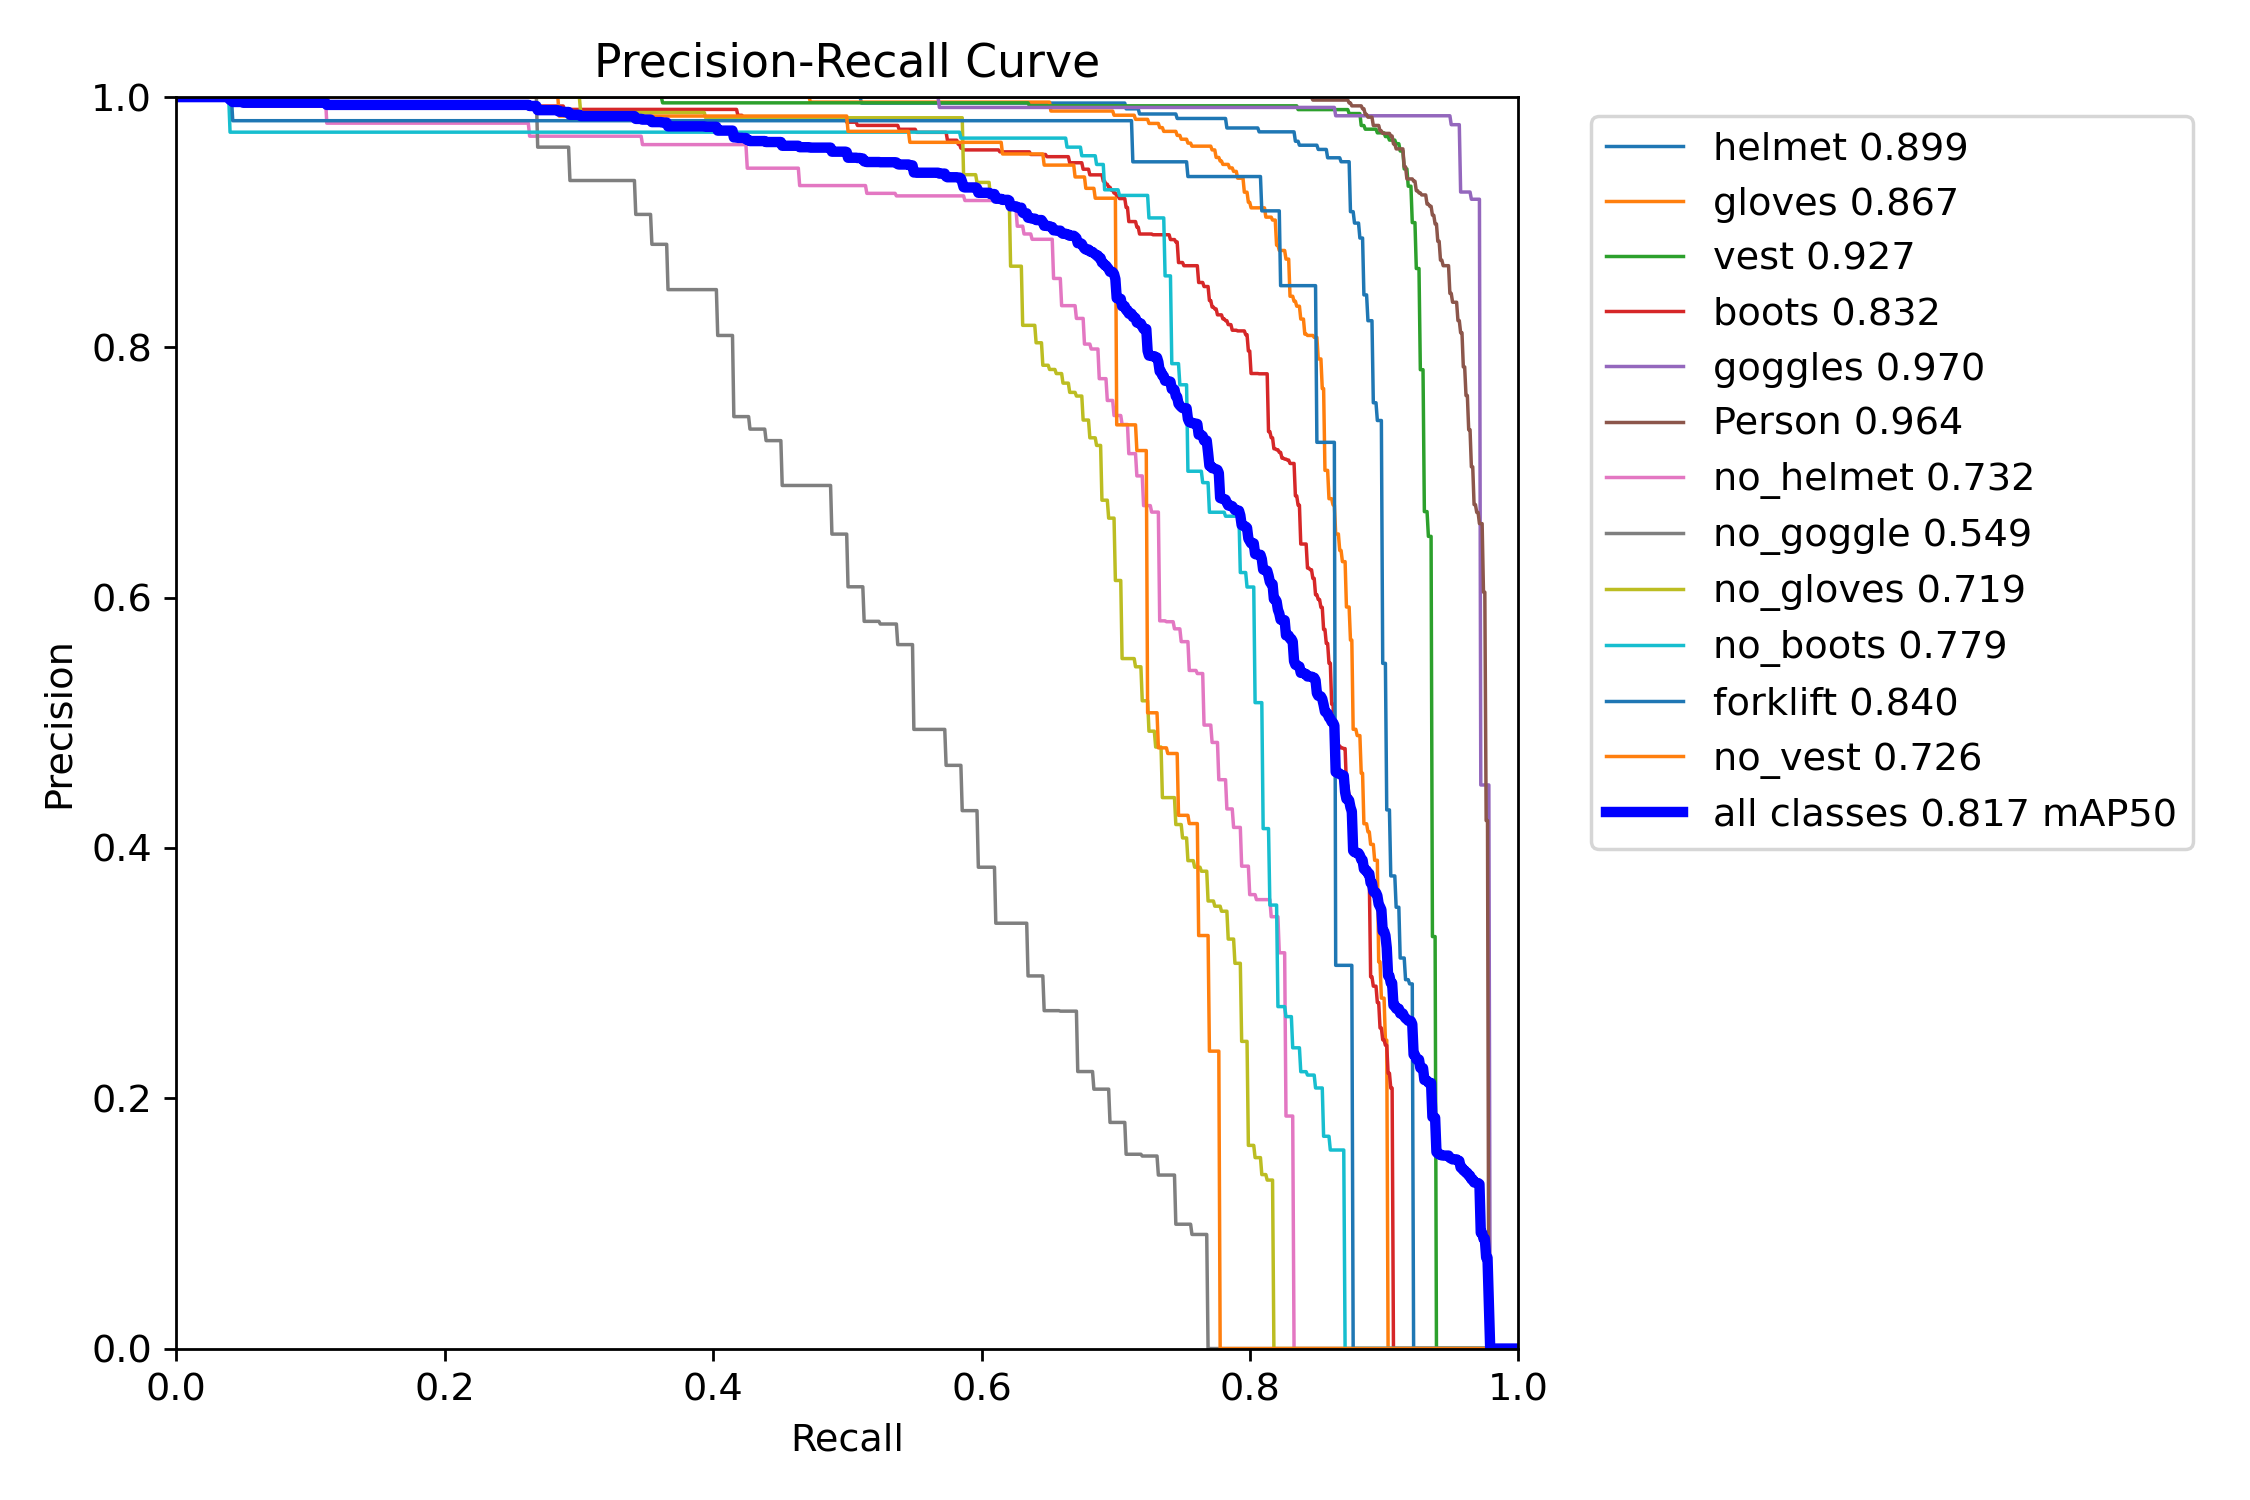

BoxF1_curve.png


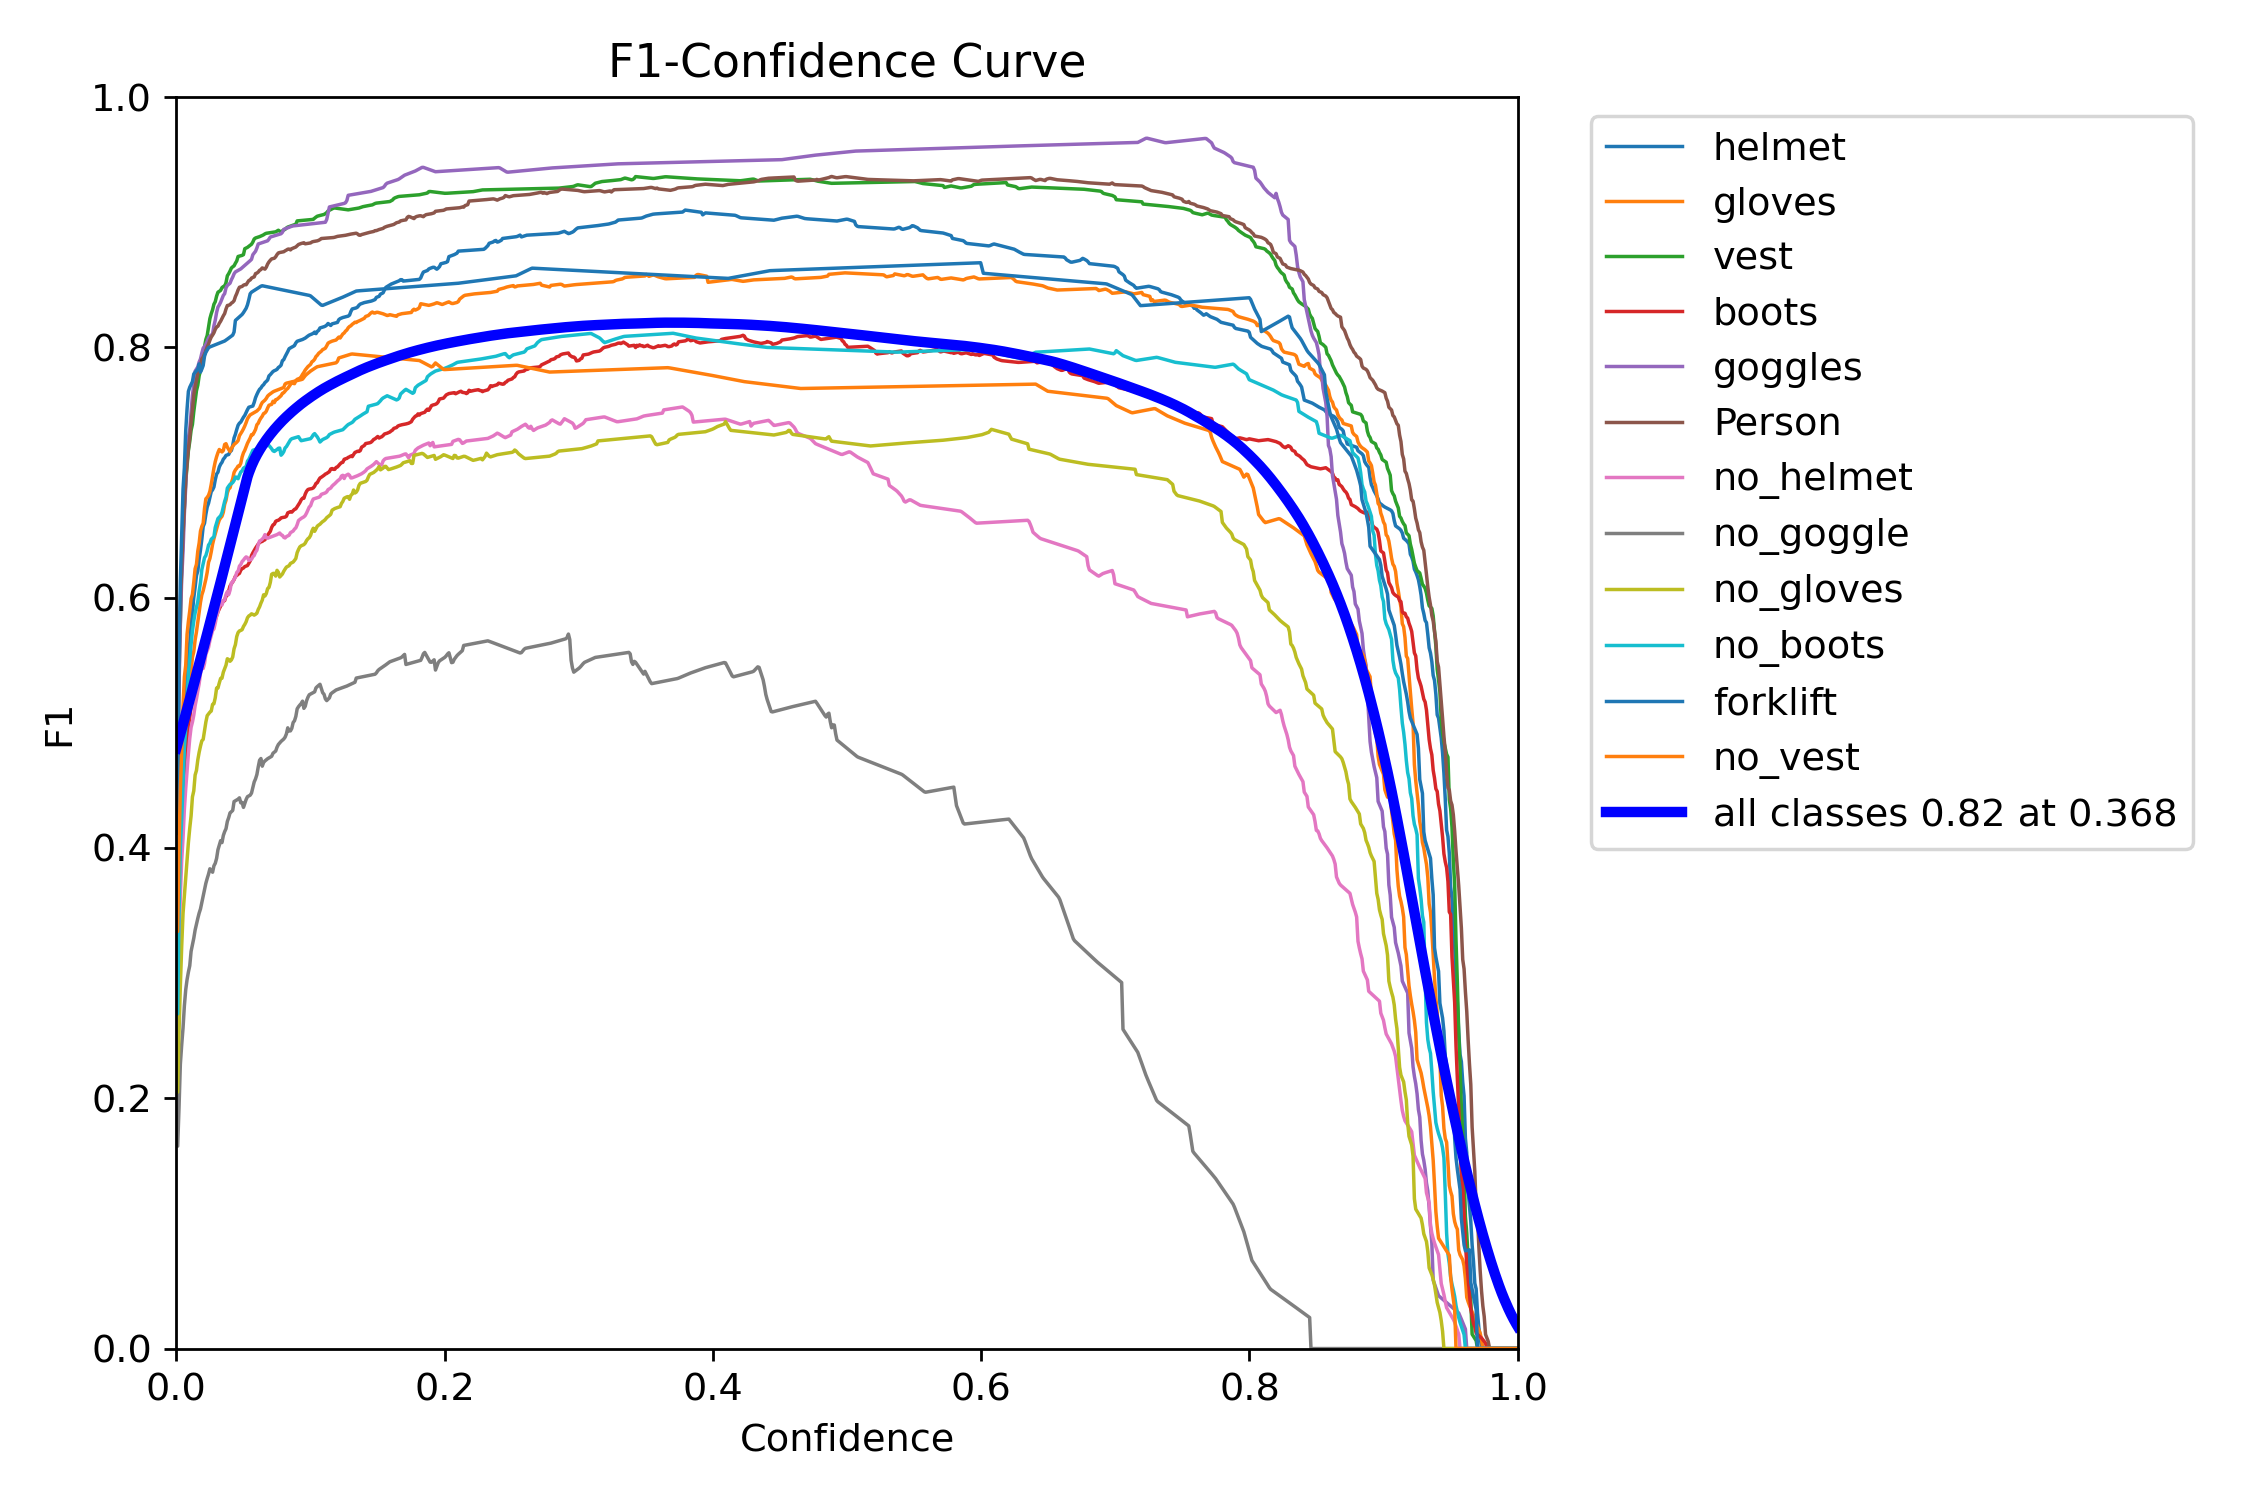

BoxP_curve.png


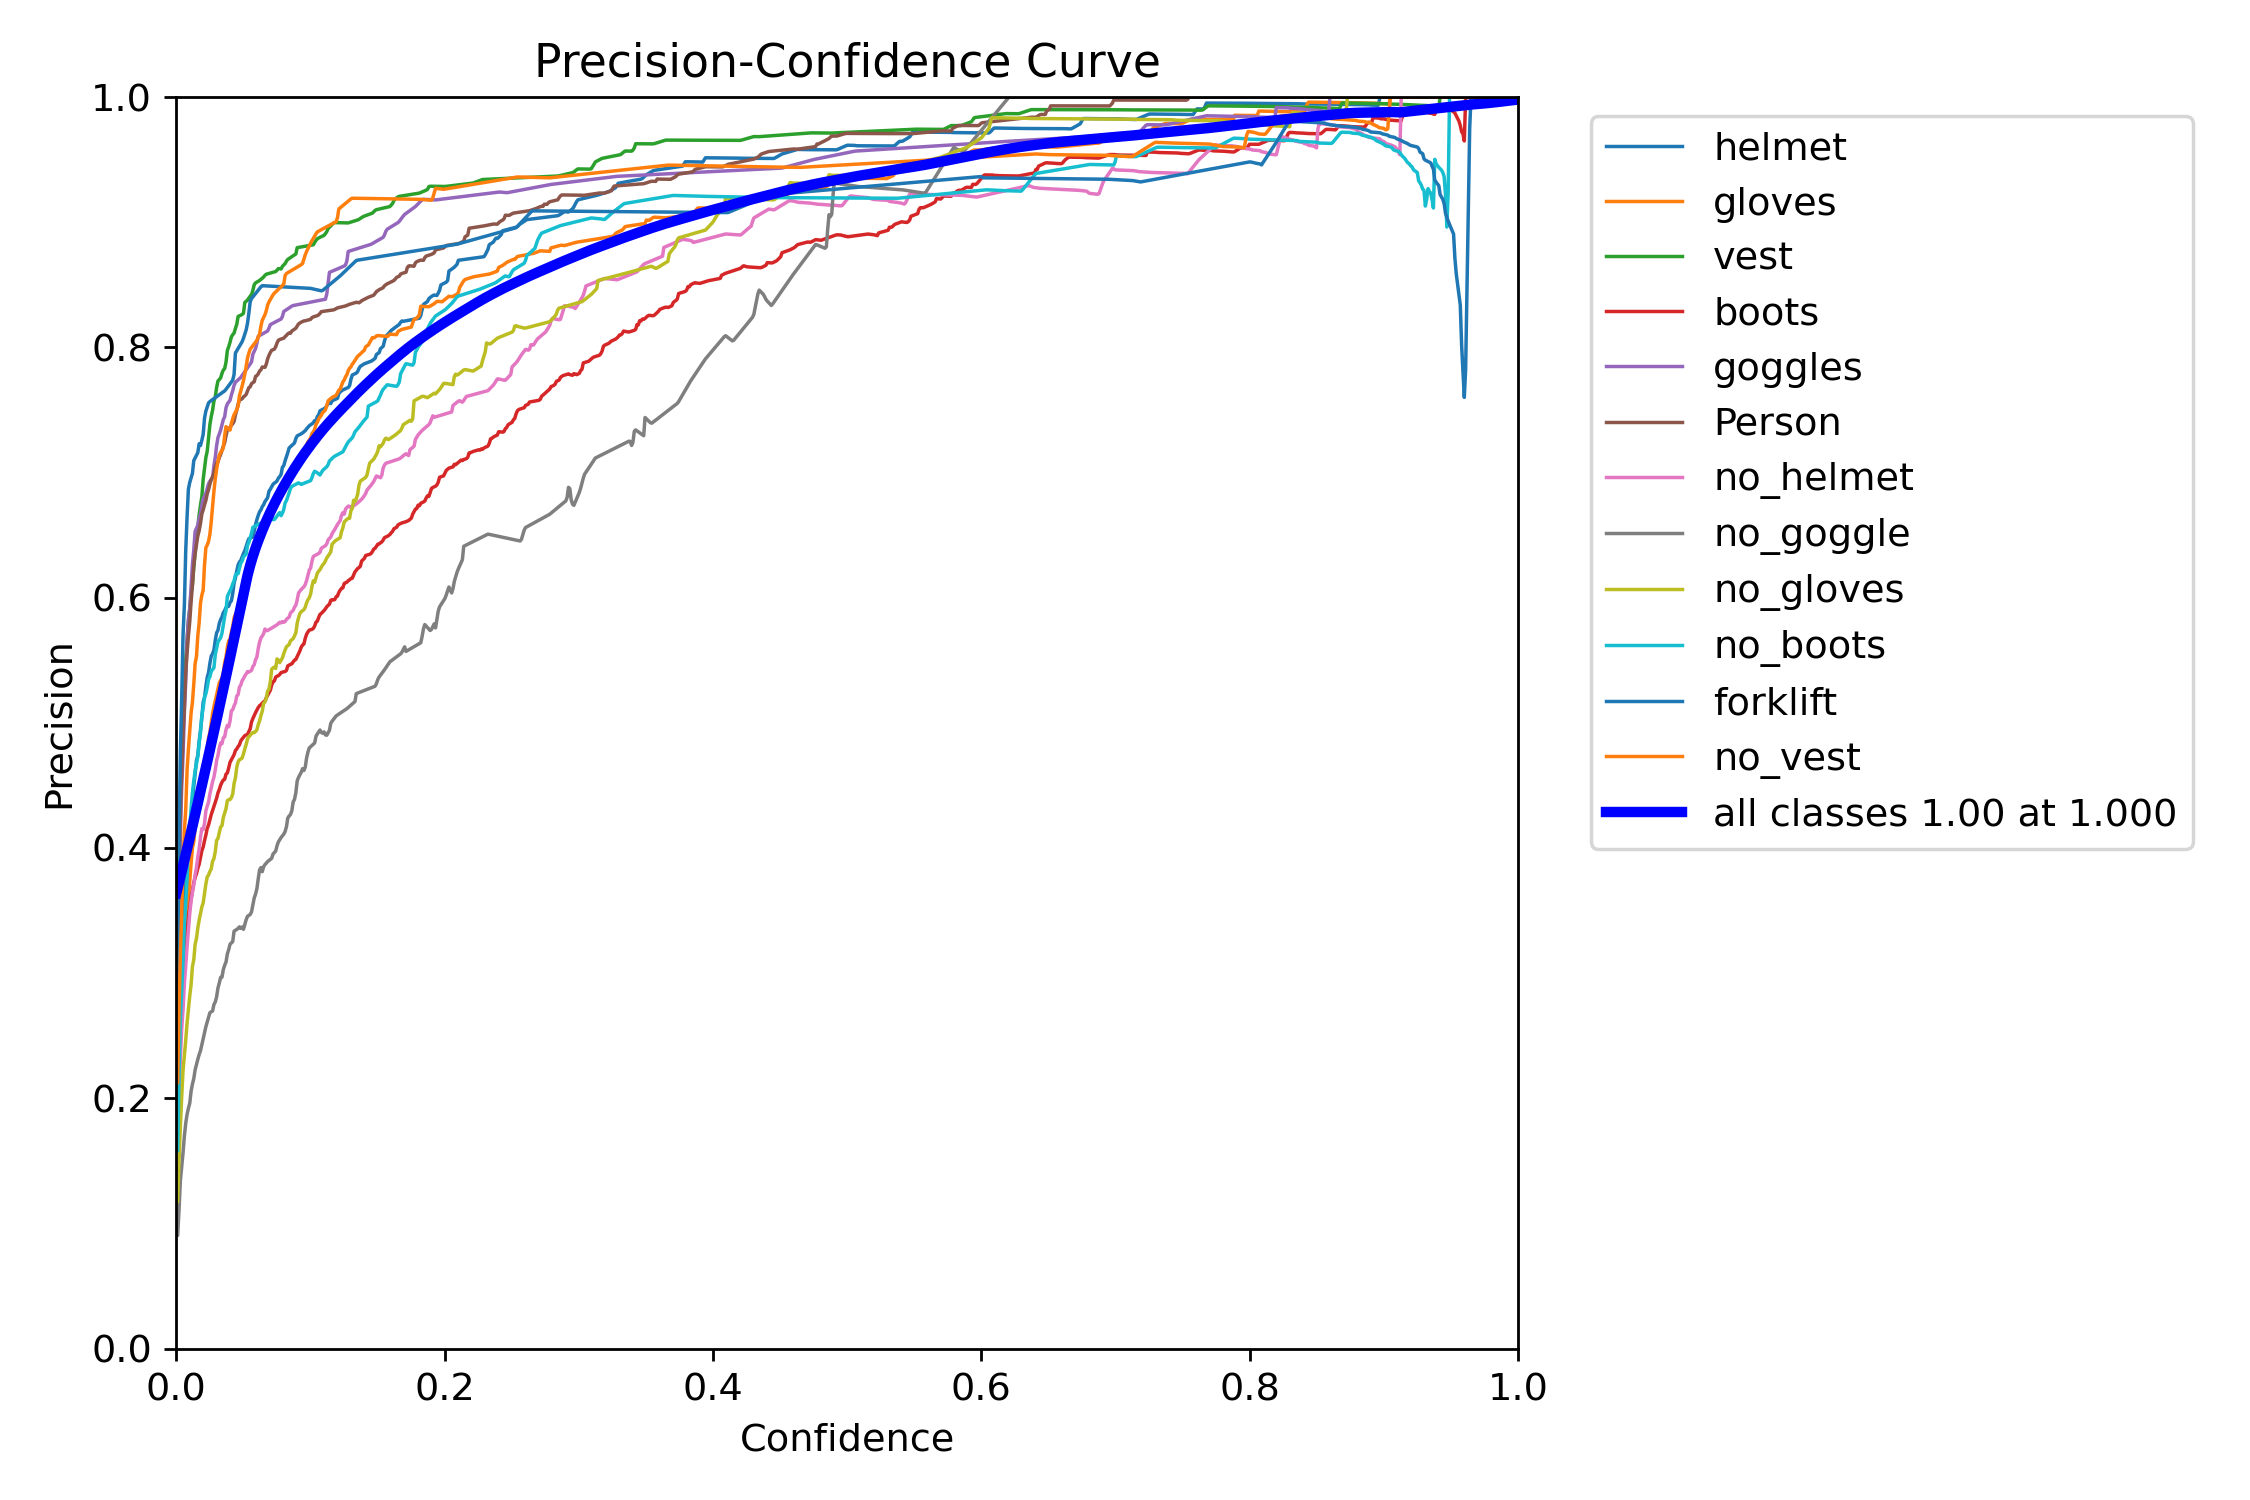

BoxR_curve.png


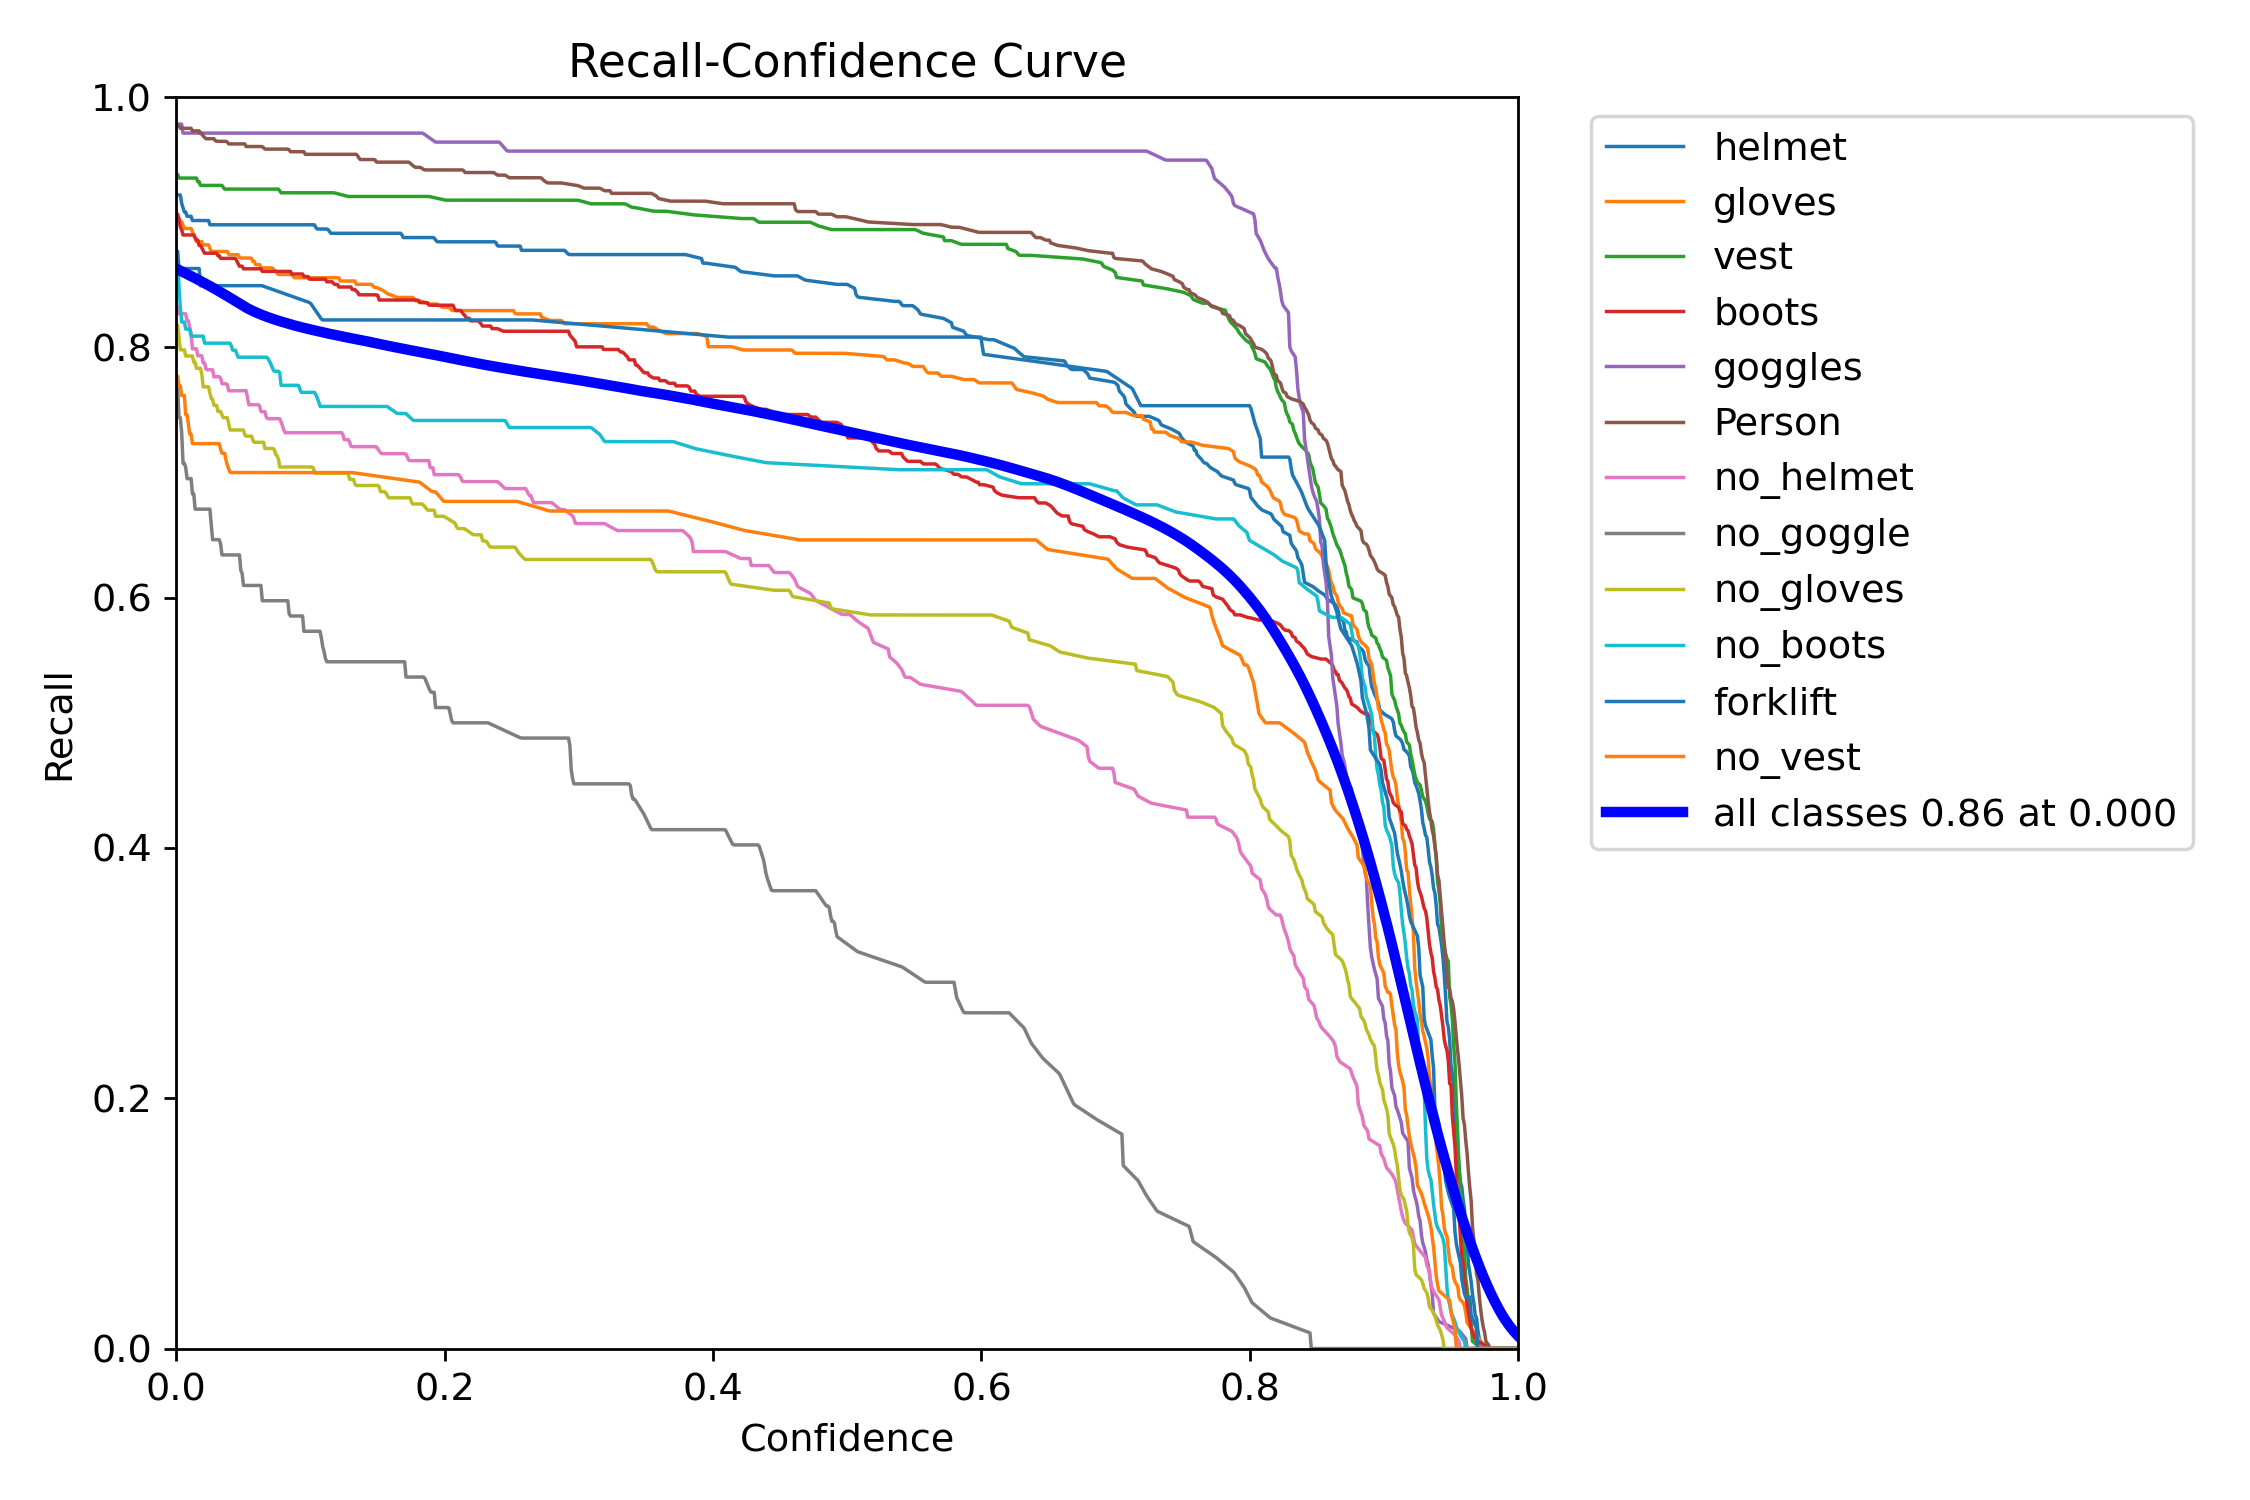

confusion_matrix_normalized.png


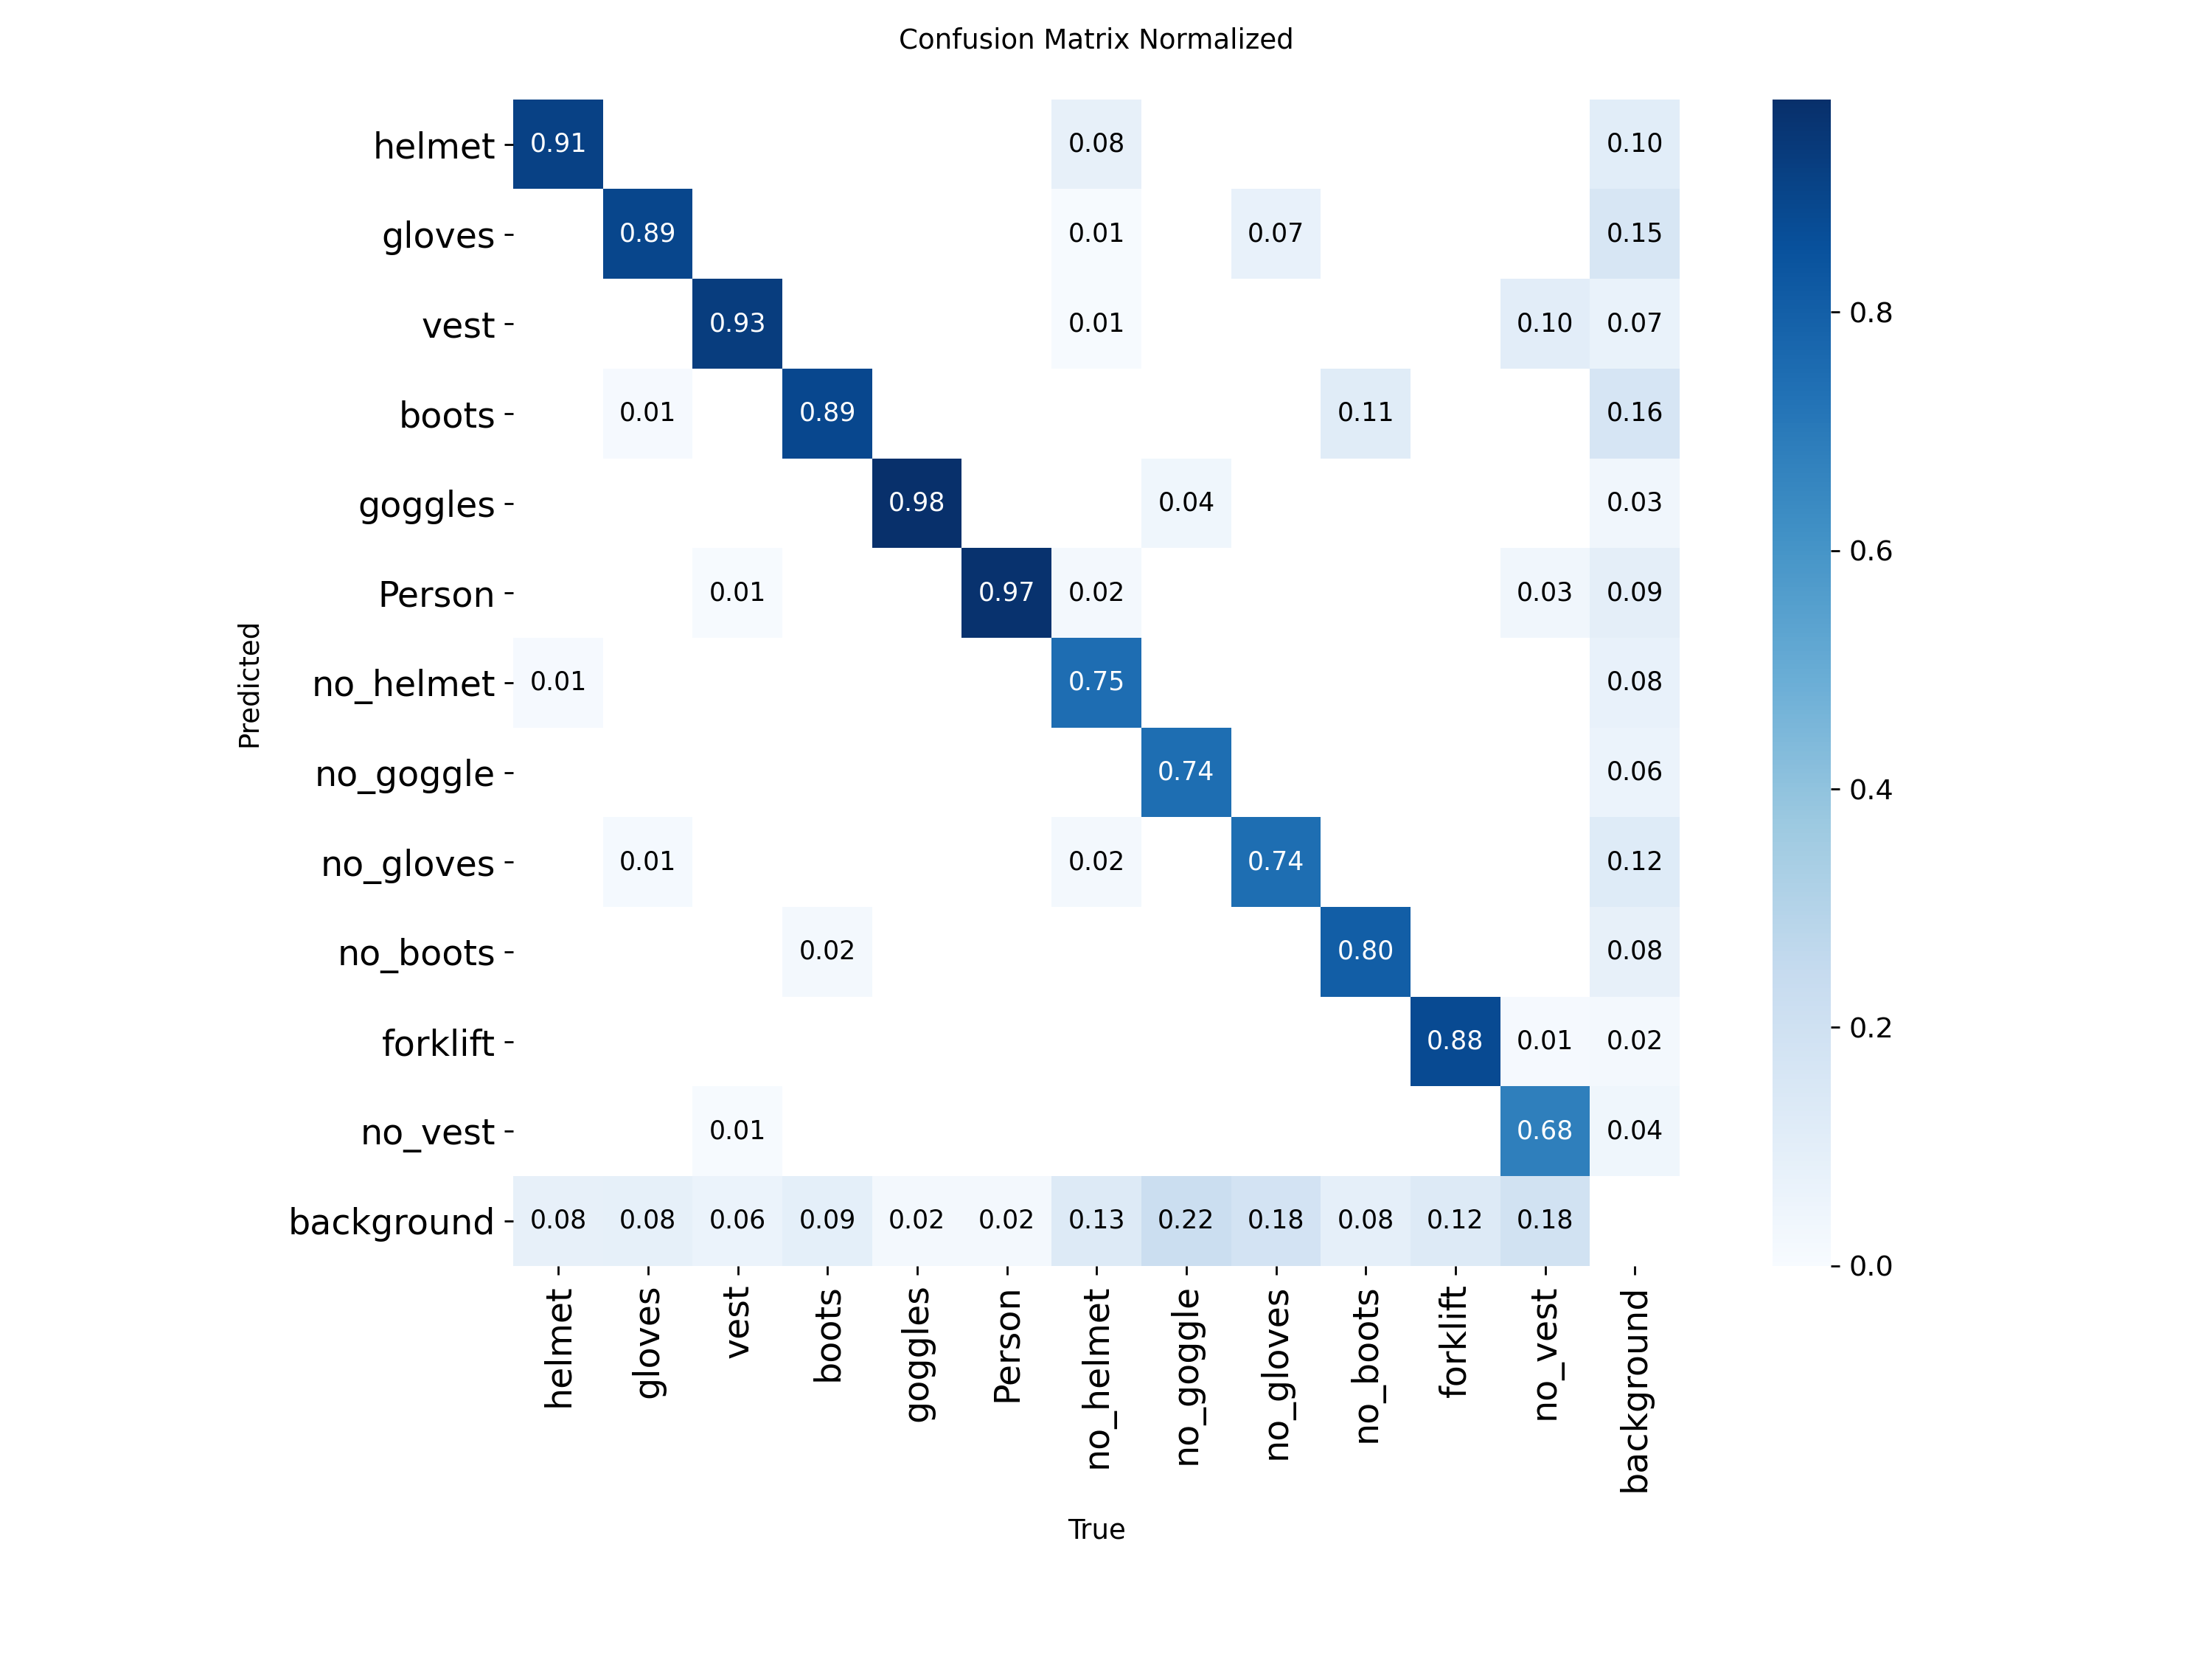

confusion_matrix.png


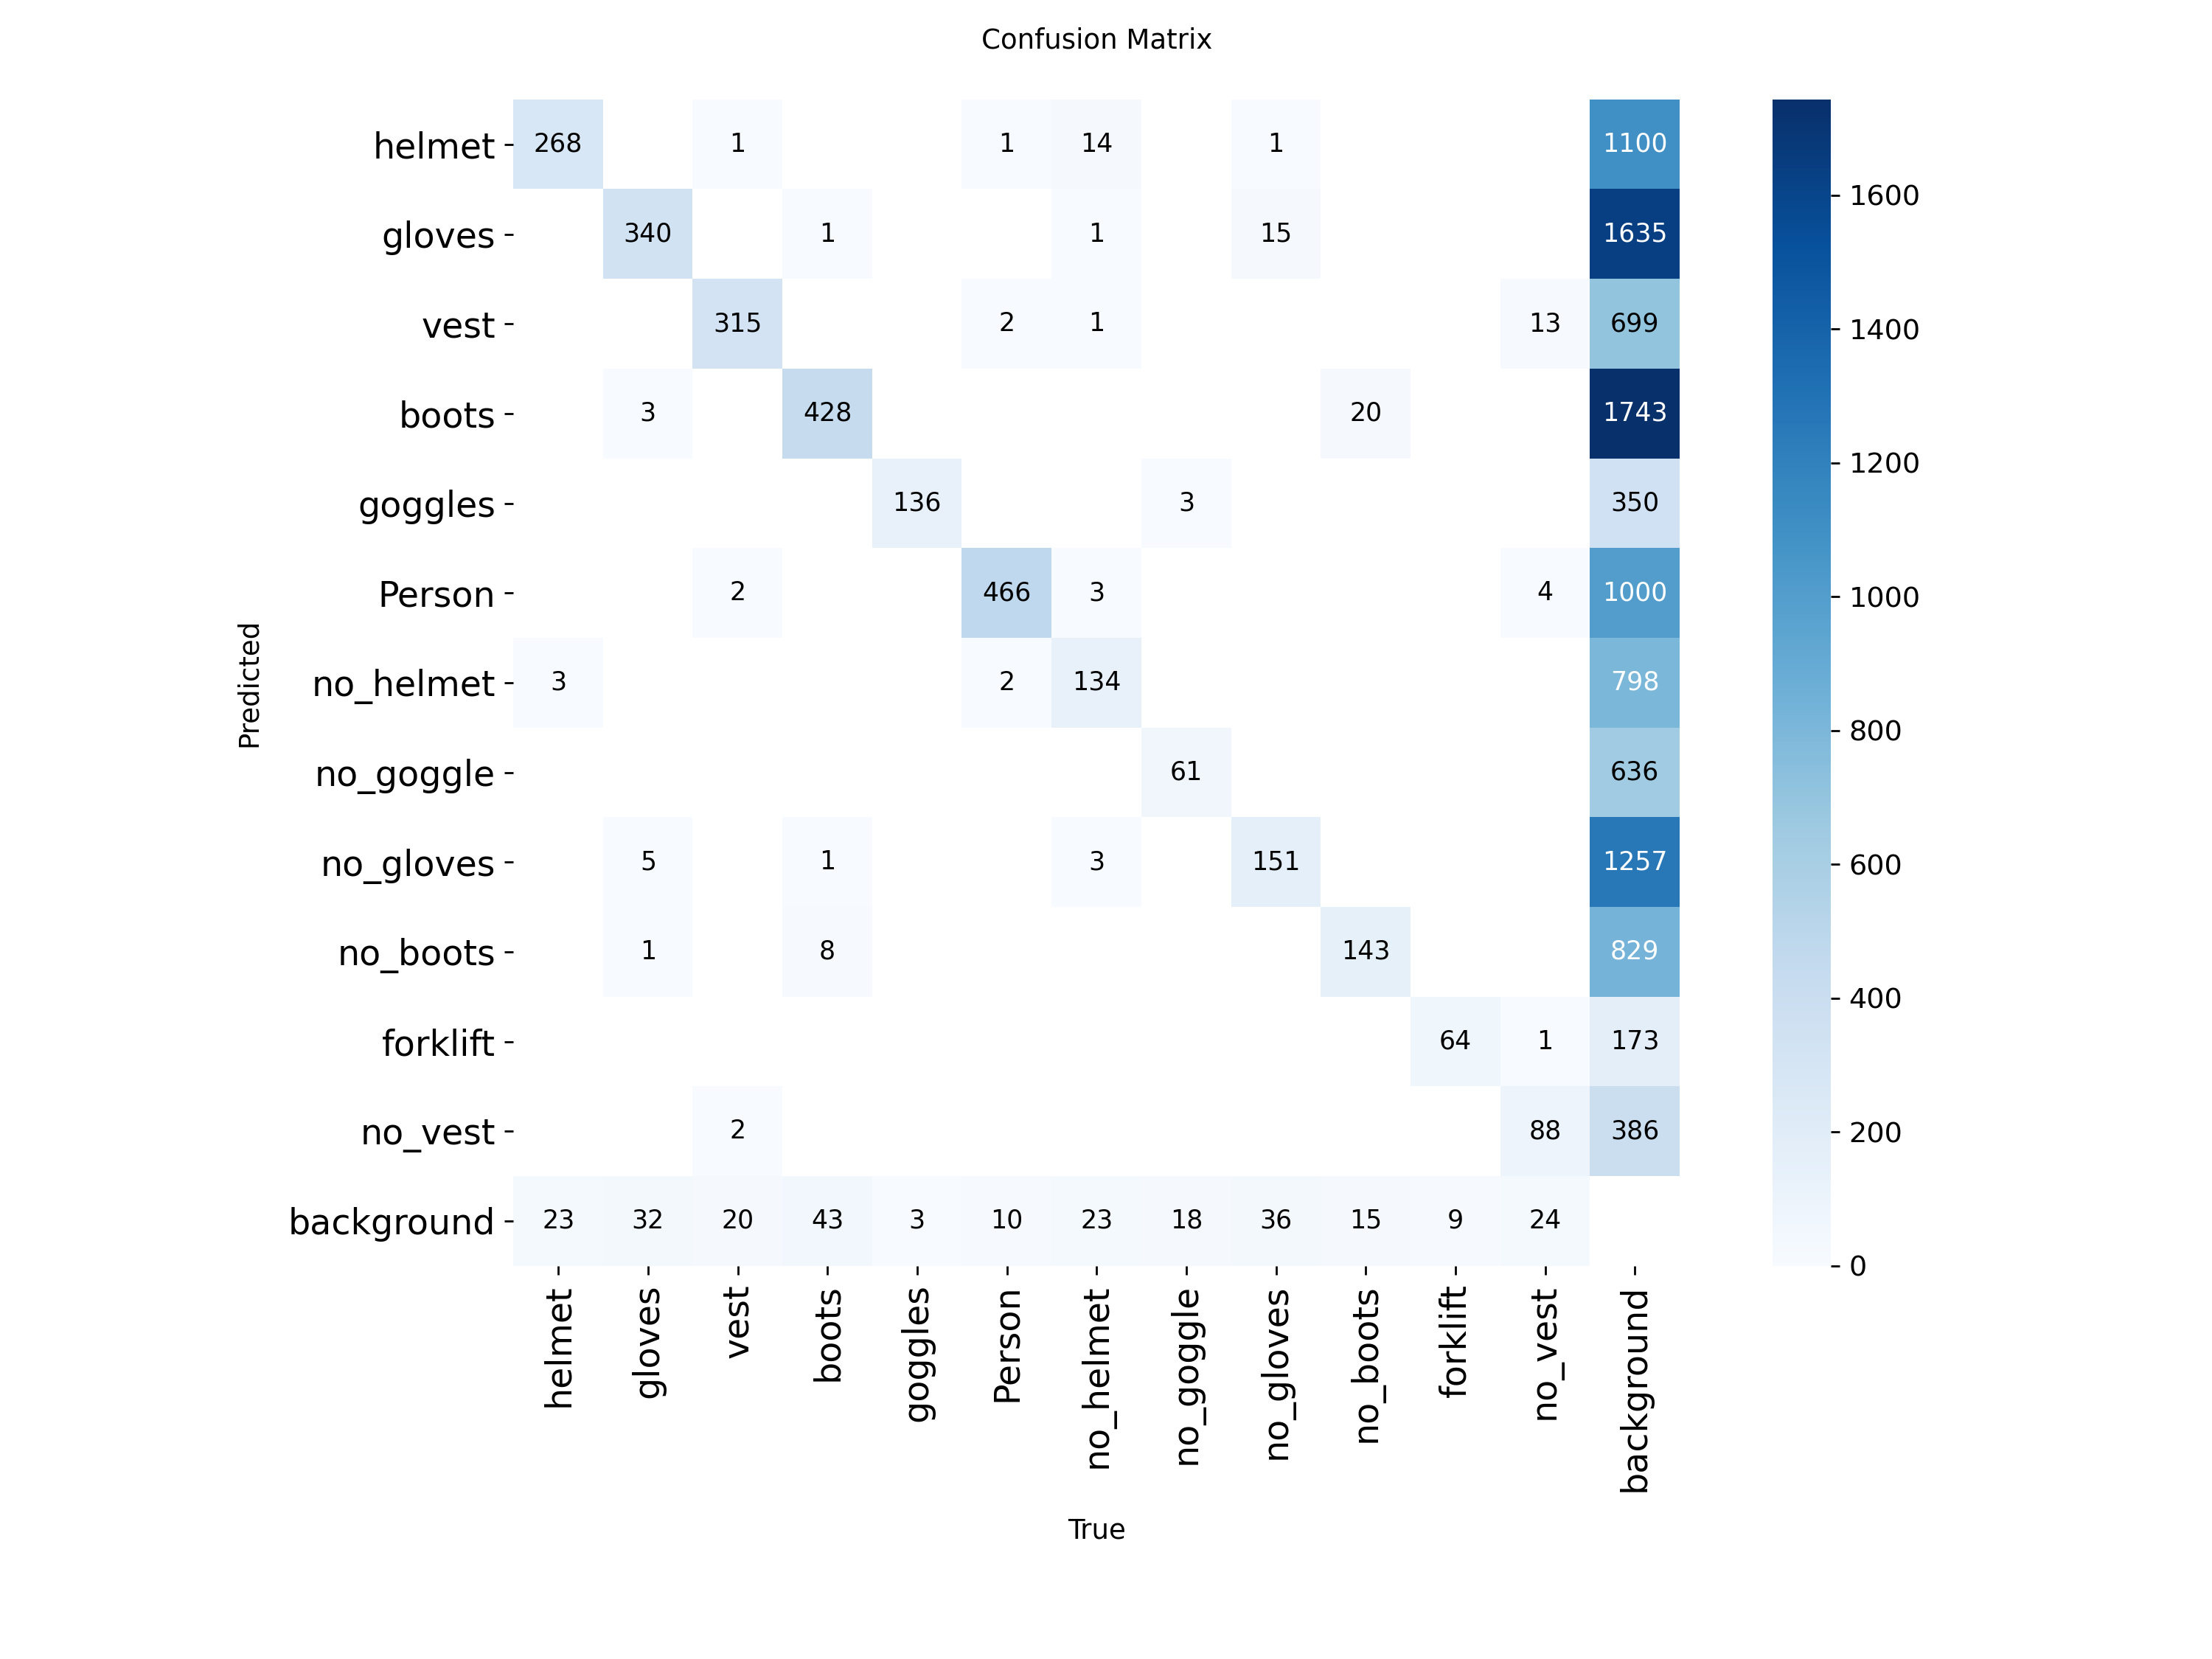

results.png


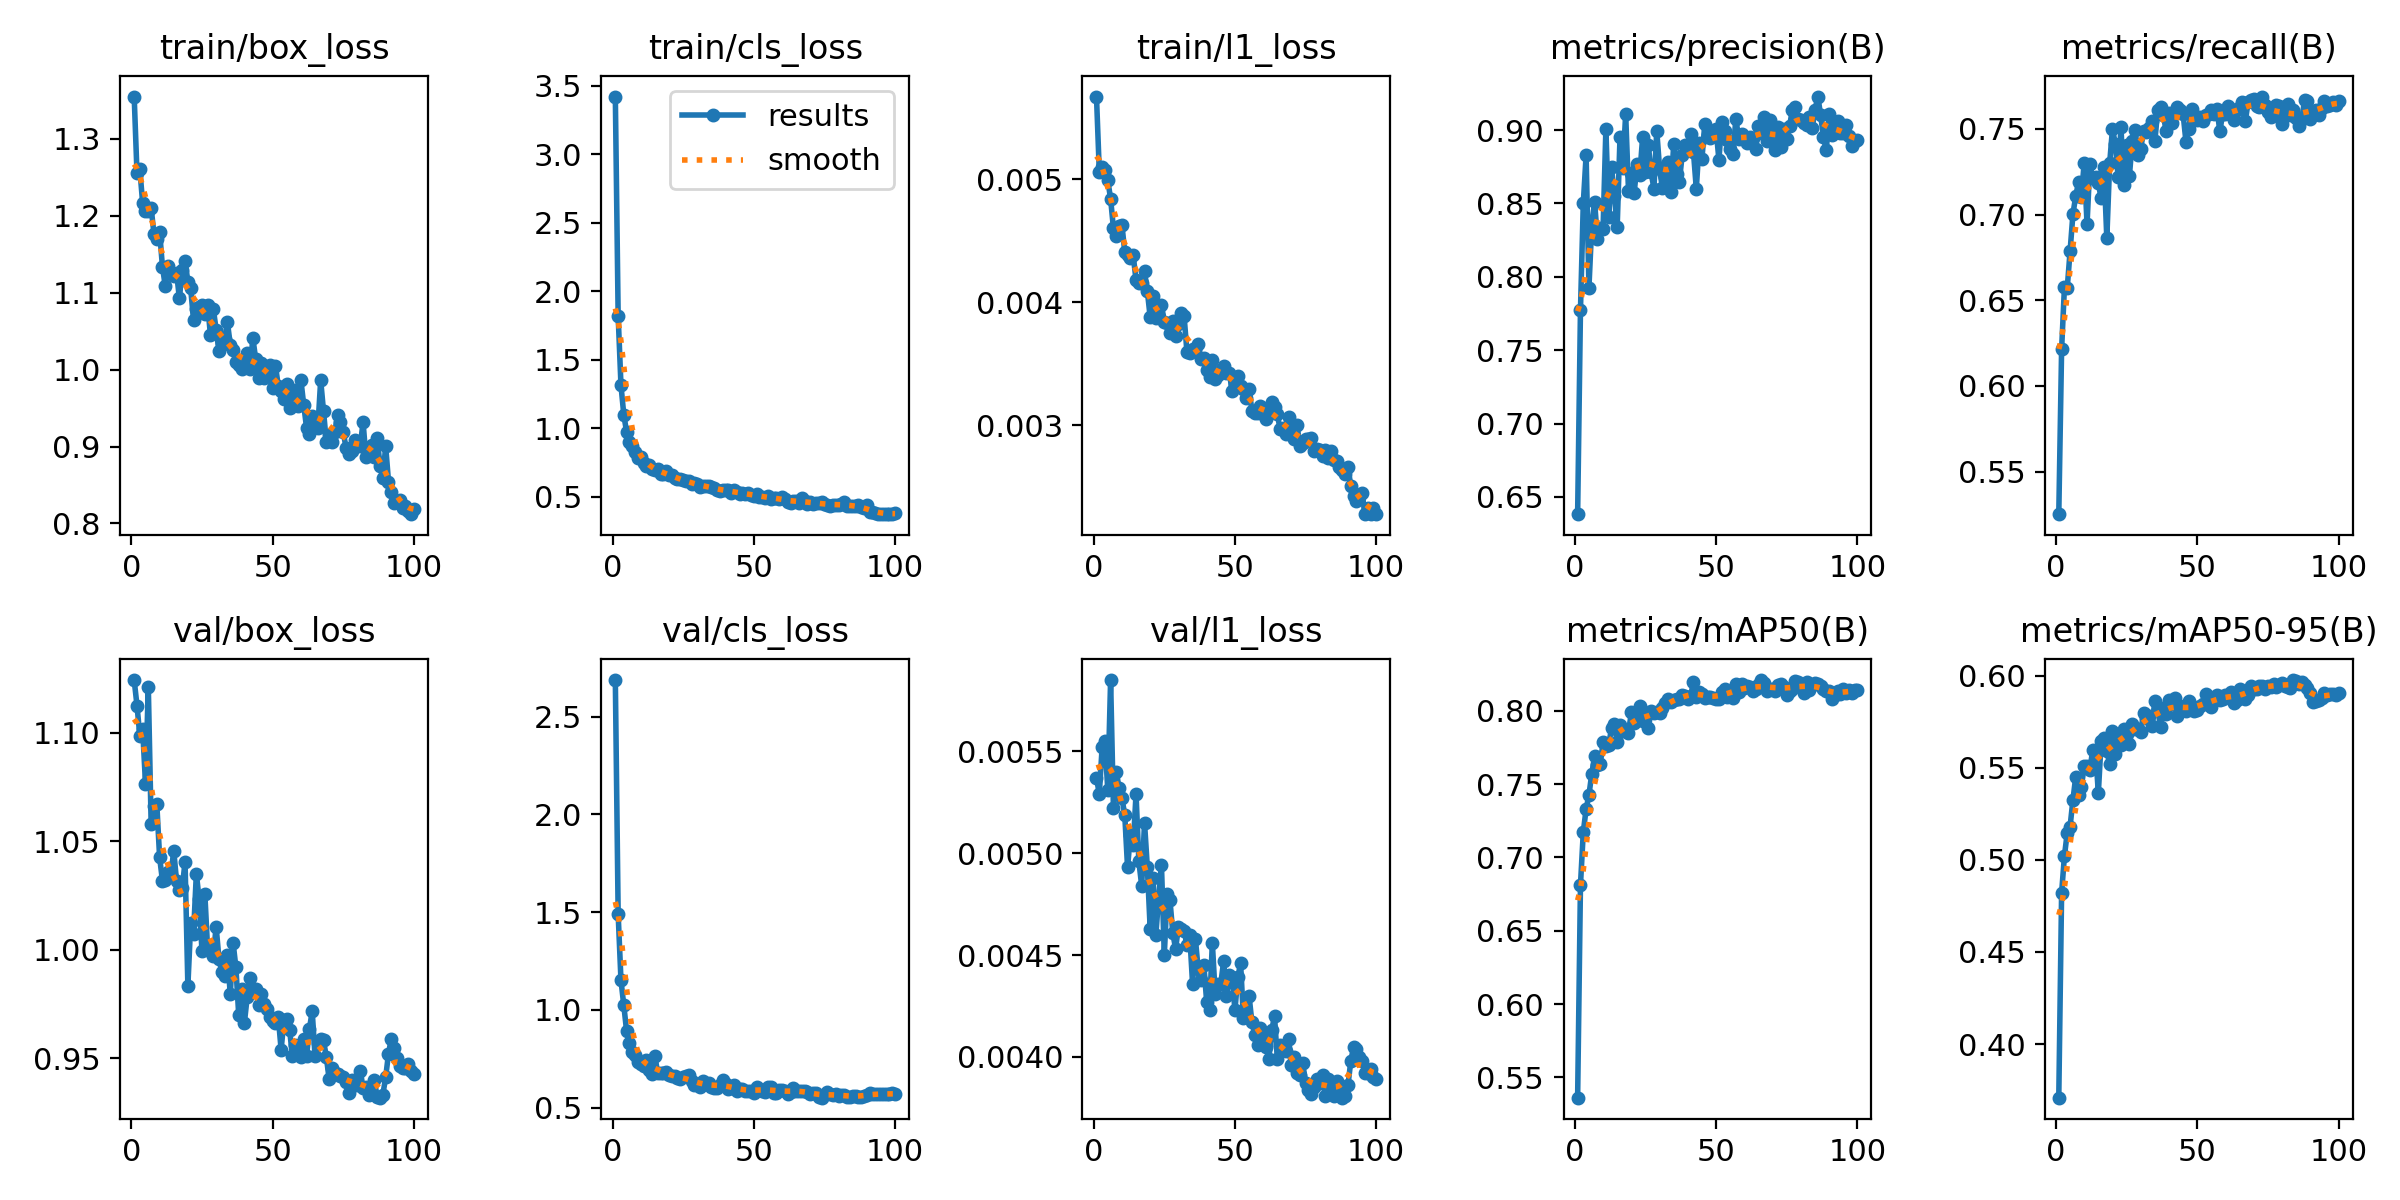

In [24]:

import glob
from IPython.display import display, Image

run_dir = os.path.join(
    PROJECT_DIR,
    "yolo26s_ppe"
)

plot_files = glob.glob(
    run_dir + "/**/*.png",
    recursive=True
)

for path in plot_files:
    print(os.path.basename(path))
    display(Image(filename=path, width= 800, height=400))

In [15]:

from google.colab import files

uploaded = files.upload()

for image_path in uploaded.keys():
    results = best_model.predict(
        source=image_path,
        conf=0.25,
        save=True,
        show_labels=True,
        show_conf=True
    )

print("Prediction completed!")


Saving vecteezy_team-of-engineer-architect-contractor-and-foreman-meeting_14290345.jpg to vecteezy_team-of-engineer-architect-contractor-and-foreman-meeting_14290345.jpg

image 1/1 /content/vecteezy_team-of-engineer-architect-contractor-and-foreman-meeting_14290345.jpg: 448x640 4 helmets, 1 gloves, 3 vests, 5 bootss, 3 goggless, 4 Persons, 4 no_glovess, 1 no_boots, 1 no_vest, 12.9ms
Speed: 5.4ms preprocess, 12.9ms inference, 1.5ms postprocess per image at shape (1, 3, 448, 640)
Results saved to /content/runs/detect/predict
Prediction completed!


In [16]:

import pandas as pd

final_results = {
    "Model": ["YOLO26s"],
    "Precision": [metrics.box.mp],
    "Recall": [metrics.box.mr],
    "F1 Score": [f1_score],
    "mAP50": [metrics.box.map50],
    "mAP75": [metrics.box.map75],
    "mAP50-95": [metrics.box.map]
}

df = pd.DataFrame(final_results)

df.to_csv(
    os.path.join(PROJECT_DIR, "evaluation_results.csv"),
    index=False
)

display(df)


,Model,Precision,Recall,F1 Score,mAP50,mAP75,mAP50-95
0,YOLO26s,0.903284,0.765178,0.828515,0.81995,0.627545,0.599018
